# Playground
Shift+Enter runs a cell.

In [5]:
from datasets import load_dataset

ds = load_dataset("google/frames-benchmark")
ds

DatasetDict({
    test: Dataset({
        features: ['Unnamed: 0', 'Prompt', 'Answer', 'wikipedia_link_1', 'wikipedia_link_2', 'wikipedia_link_3', 'wikipedia_link_4', 'wikipedia_link_5', 'wikipedia_link_6', 'wikipedia_link_7', 'wikipedia_link_8', 'wikipedia_link_9', 'wikipedia_link_10', 'wikipedia_link_11+', 'reasoning_types', 'wiki_links'],
        num_rows: 824
    })
})

In [6]:
df = ds["test"].to_pandas()
df.shape

(824, 16)

In [7]:
df[["Prompt", "Answer", "reasoning_types"]].head()

,Prompt,Answer,reasoning_types
0,If my future wife has the same first name as t...,Jane Ballou,Multiple constraints
1,Imagine there is a building called Bronte towe...,37th,Numerical reasoning | Tabular reasoning | Mult...
2,How many years earlier would Punxsutawney Phil...,87,Numerical reasoning | Multiple constraints | T...
3,"As of August 1, 2024, which country were holde...",France,Tabular reasoning | Multiple constraints | Tem...
4,What is the name of the vocalist from the firs...,Jens Kidman,Multiple constraints


In [8]:
row = df.iloc[0]
print("Q:", row["Prompt"])
print("A:", row["Answer"])
print("Type:", row["reasoning_types"])
print("Links:", row["wiki_links"])

Q: If my future wife has the same first name as the 15th first lady of the United States' mother and her surname is the same as the second assassinated president's mother's maiden name, what is my future wife's name? 
A: Jane Ballou
Type: Multiple constraints
Links: ['https://en.wikipedia.org/wiki/President_of_the_United_States', 'https://en.wikipedia.org/wiki/James_Buchanan', 'https://en.wikipedia.org/wiki/Harriet_Lane', 'https://en.wikipedia.org/wiki/List_of_presidents_of_the_United_States_who_died_in_office', 'https://en.wikipedia.org/wiki/James_A._Garfield']


In [9]:
df["reasoning_types"].str.split(" \\| ").explode().str.strip().value_counts()

reasoning_types
Multiple constraints    549
Numerical reasoning     293
Temporal reasoning      278
Tabular reasoning       236
Post processing         107
Name: count, dtype: int64

In [10]:
df["n_links"] = df["wiki_links"].apply(lambda s: len(eval(s)) if isinstance(s, str) else len(s))
df["n_links"].describe()

count    824.000000
mean       3.199029
std        1.577238
min        2.000000
25%        2.000000
50%        3.000000
75%        4.000000
max       11.000000
Name: n_links, dtype: float64

In [11]:
num = df[df["reasoning_types"].str.contains("Numerical")]
print(len(num), "numerical questions")
num[["Prompt", "Answer"]].head(3)

293 numerical questions


,Prompt,Answer
1,Imagine there is a building called Bronte towe...,37th
2,How many years earlier would Punxsutawney Phil...,87
5,"According to the 2000 United States census, wh...",506000


Matplotlib is building the font cache; this may take a moment.


<Axes: title={'center': 'Wikipedia pages needed per question'}, xlabel='n_links'>

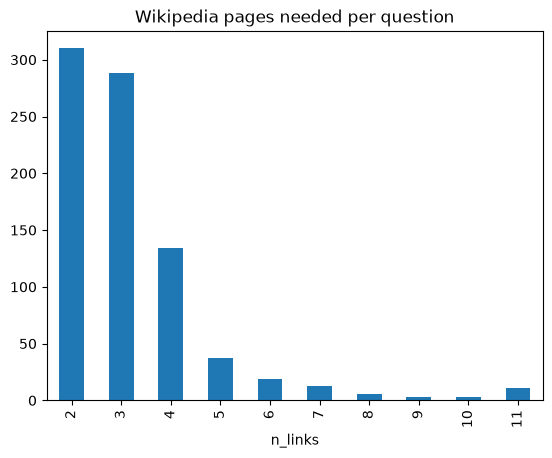

In [12]:
df["n_links"].value_counts().sort_index().plot(kind="bar", title="Wikipedia pages needed per question")

In [16]:
user = {"name": "Alice", "role": "admin"}
print(list(user.values()))  # Output: dict_keys(['name', 'role'])

['Alice', 'admin']


In [15]:
for key, value in user.items():
    print(f"{key}: {value}")


name: Alice
role: admin
